In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create a realistic HR Employee Attrition Dataset
np.random.seed(42)
n_employees = 8000

departments = np.random.choice(['Sales', 'IT & Development', 'HR', 'Finance', 'Operations'], n_employees, p=[0.30, 0.30, 0.10, 0.15, 0.15])
monthly_income = np.random.randint(25000, 120000, n_employees)
years_at_company = np.random.randint(1, 15, n_employees)
overtime = np.random.choice(['Yes', 'No'], n_employees, p=[0.35, 0.65])
job_satisfaction = np.random.randint(1, 5, n_employees) # 1 = Low, 4 = Very High

# Simulate realistic attrition logic (higher if Overtime='Yes', low income, or low satisfaction)
attrition_prob = (
    0.08
    + np.where(overtime == 'Yes', 0.18, 0.0)
    + np.where(monthly_income < 45000, 0.12, 0.0)
    + np.where(job_satisfaction <= 2, 0.10, 0.0)
)
attrition = [np.random.choice(['Yes', 'No'], p=[p, 1 - p]) for p in attrition_prob]

df = pd.DataFrame({
    'Employee_ID': range(1001, 1001 + n_employees),
    'Department': departments,
    'Monthly_Income': monthly_income,
    'Years_At_Company': years_at_company,
    'OverTime': overtime,
    'Job_Satisfaction': job_satisfaction,
    'Attrition': attrition
})

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (8000, 7)


,Employee_ID,Department,Monthly_Income,Years_At_Company,OverTime,Job_Satisfaction,Attrition
0,1001,IT & Development,55346,2,No,3,No
1,1002,Operations,113284,12,No,1,No
2,1003,Finance,116384,4,No,4,No
3,1004,IT & Development,78526,9,No,4,No
4,1005,Sales,98143,2,No,4,No


In [7]:
# Check for missing values and data types
print("Missing Values:\n", df.isnull().sum())
print("\nDataset Summary:")
print(df.describe())

# Overall Attrition Rate
attrition_rate = (df['Attrition'].value_counts(normalize=True) * 100).round(2)
print("\nOverall Attrition Percentage:\n", attrition_rate)

Missing Values:
 Employee_ID         0
Department          0
Monthly_Income      0
Years_At_Company    0
OverTime            0
Job_Satisfaction    0
Attrition           0
dtype: int64

Dataset Summary:
       Employee_ID  Monthly_Income  Years_At_Company  Job_Satisfaction
count   8000.00000     8000.000000       8000.000000       8000.000000
mean    5000.50000    72123.733625          7.441375          2.494625
std     2309.54541    27759.511059          4.033156          1.112711
min     1001.00000    25005.000000          1.000000          1.000000
25%     3000.75000    47484.500000          4.000000          2.000000
50%     5000.50000    72162.000000          7.000000          2.000000
75%     7000.25000    96714.250000         11.000000          3.000000
max     9000.00000   119990.000000         14.000000          4.000000

Overall Attrition Percentage:
 Attrition
No     77.42
Yes    22.58
Name: proportion, dtype: float64


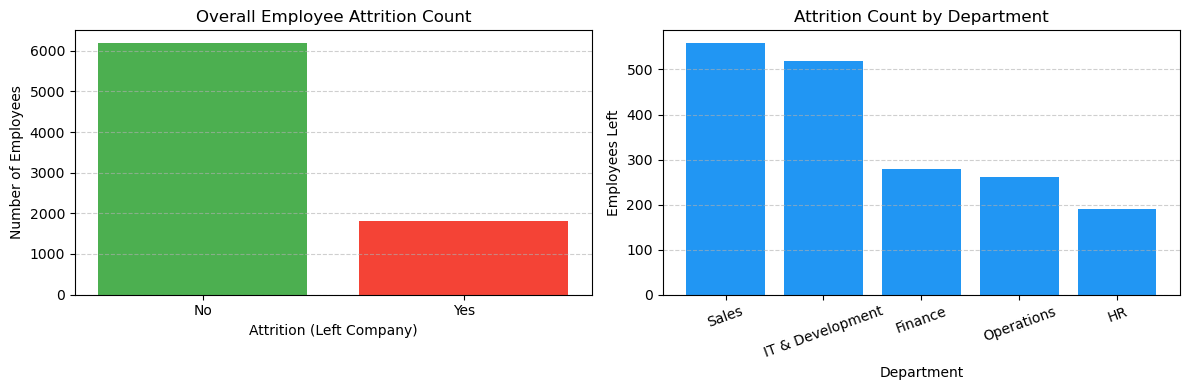

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Overall Attrition Count
attrition_counts = df['Attrition'].value_counts()
axes[0].bar(attrition_counts.index, attrition_counts.values, color=['#4CAF50', '#F44336'])
axes[0].set_title('Overall Employee Attrition Count')
axes[0].set_xlabel('Attrition (Left Company)')
axes[0].set_ylabel('Number of Employees')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Plot 2: Attrition by Department
dept_attrition = df[df['Attrition'] == 'Yes']['Department'].value_counts()
axes[1].bar(dept_attrition.index, dept_attrition.values, color='#2196F3')
axes[1].set_title('Attrition Count by Department')
axes[1].set_xlabel('Department')
axes[1].set_ylabel('Employees Left')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

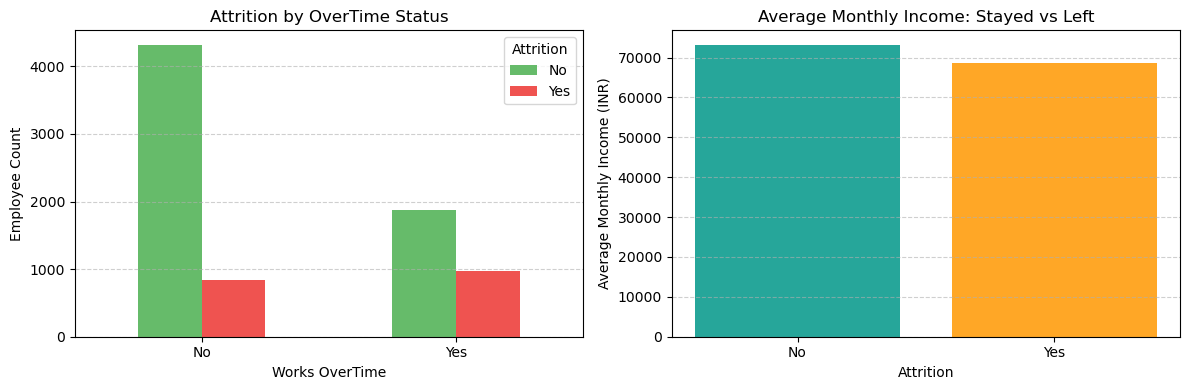

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Overtime vs Attrition
overtime_ct = pd.crosstab(df['OverTime'], df['Attrition'])
overtime_ct.plot(kind='bar', ax=axes[0], color=['#66BB6A', '#EF5350'])
axes[0].set_title('Attrition by OverTime Status')
axes[0].set_xlabel('Works OverTime')
axes[0].set_ylabel('Employee Count')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Plot 2: Average Monthly Income (Stayed vs Left)
avg_income = df.groupby('Attrition')['Monthly_Income'].mean()
axes[1].bar(avg_income.index, avg_income.values, color=['#26A69A', '#FFA726'])
axes[1].set_title('Average Monthly Income: Stayed vs Left')
axes[1].set_xlabel('Attrition')
axes[1].set_ylabel('Average Monthly Income (INR)')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [10]:
# Generate key analytical metrics for reporting
avg_income_left = df[df['Attrition'] == 'Yes']['Monthly_Income'].mean()
avg_income_stayed = df[df['Attrition'] == 'No']['Monthly_Income'].mean()
overtime_attrition_rate = (df[df['OverTime'] == 'Yes']['Attrition'].value_counts(normalize=True)['Yes'] * 100)

print("--- KEY HR ANALYTICS INSIGHTS ---")
print(f"1. Average Income of Employees Who Left: INR {avg_income_left:,.0f}")
print(f"2. Average Income of Employees Who Stayed: INR {avg_income_stayed:,.0f}")
print(f"3. Attrition Rate Among Employees Working OverTime: {overtime_attrition_rate:.1f}%")
print("4. Highest Attrition Departments:", df[df['Attrition'] == 'Yes']['Department'].value_counts().head(2).to_dict())

--- KEY HR ANALYTICS INSIGHTS ---
1. Average Income of Employees Who Left: INR 68,592
2. Average Income of Employees Who Stayed: INR 73,153
3. Attrition Rate Among Employees Working OverTime: 34.2%
4. Highest Attrition Departments: {'Sales': 559, 'IT & Development': 518}
